Kaarina Mattika, CS87A, Section 1758
https://github.com/kmattika/cs82a-portfolio

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [2]:
df = pd.read_csv(r'C:\Users\kamat\Downloads\titanic_train.csv')
display(df.head(10))
display(df.shape)
display(df.info())
display(df.describe())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


(891, 12)

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


None

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [3]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch']
X = df[features].copy()
y = df['Survived']

I chose these five features for inclusion as they would be the most impactful attributes for survival. The class of the passenger, which determined which part of the ship they would have resided in, is one of the more critical attributes. Sex and Age are both directly individually impactful, while Sibling-Spouse and Parent-Children are both indirectly individually impactful. PassengerId, Name, Ticket, and Embarked are string values not related to survivability and are omitted. Cabin, while if we had time to map the ship itself into zones would be helpful, is an abstraction of Pclass and is omitted. Fare is also an abstractio of Pclass and omitted.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

X_train = X_train.copy()
X_test = X_test.copy()

In [5]:
median_age = X_train['Age'].median()
X_train['Age'] = X_train['Age'].fillna(median_age)
X_test['Age'] = X_test['Age'].fillna(median_age)

In [6]:
sex_codes = {'male': 0, 'female': 1}
X_train['Sex'] = X_train['Sex'].map(sex_codes)
X_test['Sex'] = X_test['Sex'].map(sex_codes)

In [7]:
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train);

In [8]:
y_pred = model.predict(X_test)
train_accuracy = model.score(X_train, y_train)
test_accuracy = accuracy_score(y_test, y_pred)

In [9]:
print(f'Training rows: {len(X_train)}')
print(f'Test rows: {len(X_test)}')
print(f'Training median age: {median_age:.2f}')
print(f'Training accuracy: {train_accuracy:.2%}')
print(f'Test accuracy: {test_accuracy:.2%}')

Training rows: 623
Test rows: 268
Training median age: 29.00
Training accuracy: 82.99%
Test accuracy: 78.36%


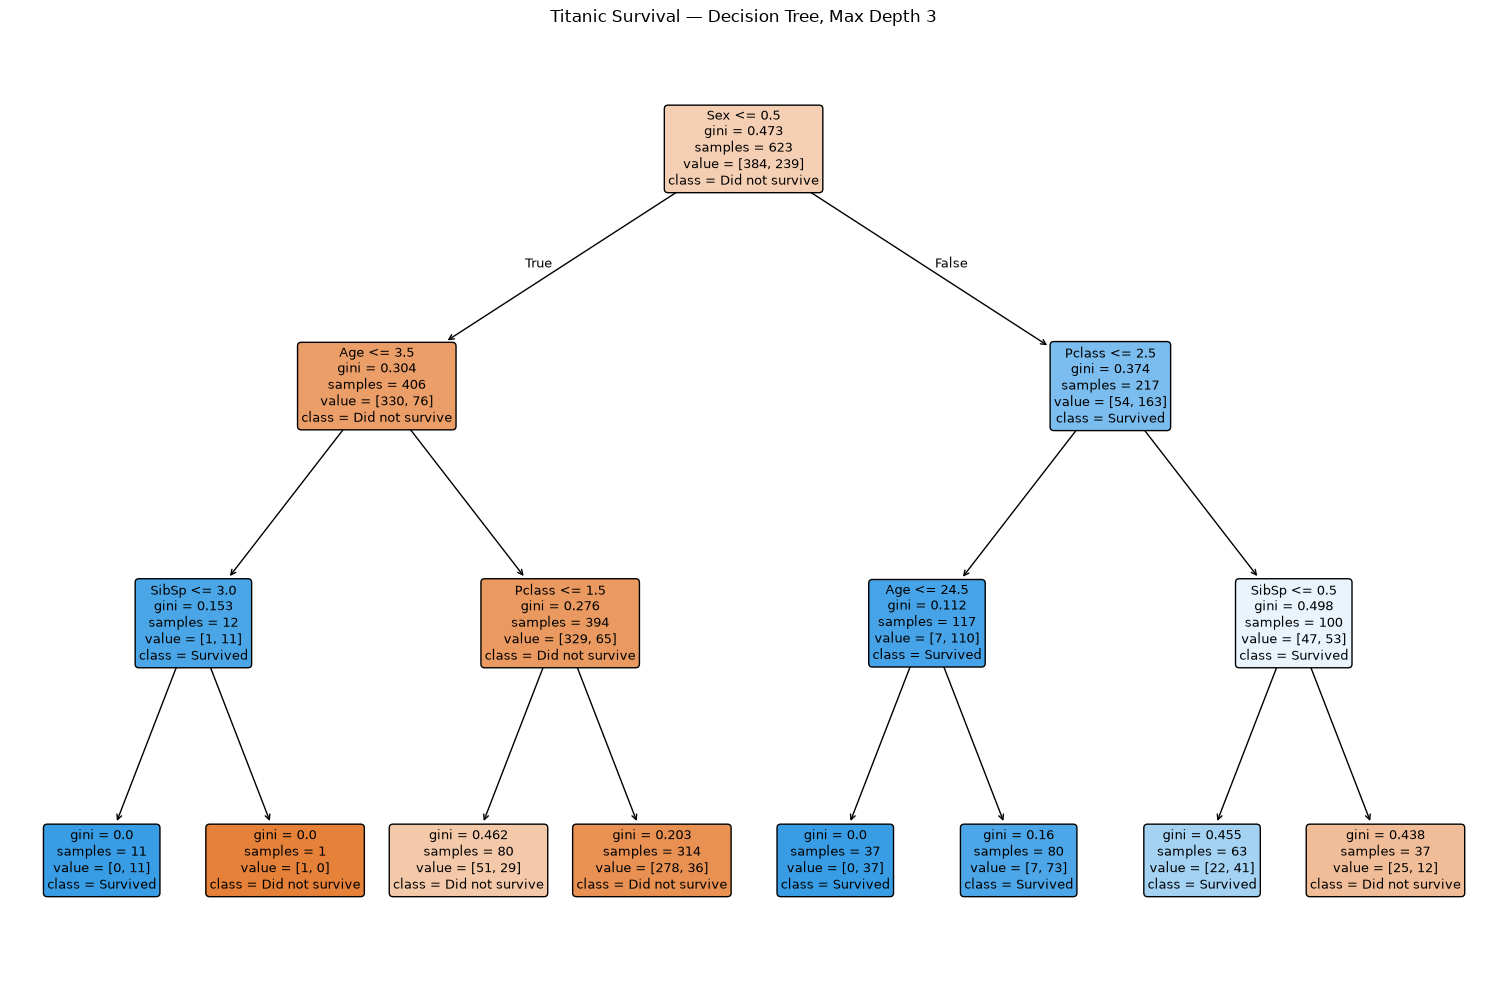

In [10]:
plt.figure(figsize=(15, 10))

plot_tree(
    model,
    feature_names=features,
    class_names=['Did not survive', 'Survived'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Titanic Survival — Decision Tree, Max Depth 3')
plt.tight_layout()
plt.show()

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display(
    pd.DataFrame(
        cm,
        index=['Actual DNS', 'Actual S'],
        columns=['Predicted DNS', 'Predicted S']
    )
)

,Predicted DNS,Predicted S
Actual DNS,151,14
Actual S,44,59


We can see that the decision tree begins sorting by sex - women are predicted to survive more than men. We then see, among men, that most boys three or younger are predicted to survive, and that only one of twelve of that population is not predicted to survive, based on sibling count. Among boys and men over the age of three, those in first class had a higher likelihood of surviving, although because the proportion of survivors in both classes (first class and second / third class) is under 50%, the tree predicts that both groups will not survive. Among women, it's the opposite - there is an overwhelming prediction of survivability across class and age, and the only prediction made for non-survival is among third class women without a spouse or sibling.

In our confusion matrix, we have 44 false positives and 14 false negatives (for a total of 58), which means the model is over-pessemistic for survival. Below, we can see every incorrectly predicted datapoint from our model - third class passengers are overwhelmingly represented within this error set. Thus, more refinement in this model, a different model, or more data refinement may be needed in order to correctly account for this class split.

In [12]:
test_results = df.loc[
    X_test.index,
    ['PassengerId', 'Name', 'Sex', 'Pclass', 'Age', 'SibSp', 'Survived']
].copy()

test_results['Predicted'] = model.predict(X_test)

errors = test_results[
    test_results['Survived'] != test_results['Predicted']
]

with pd.option_context('display.max_rows', None):
    display(errors.sort_values(by=['Pclass', 'PassengerId']))

,PassengerId,Name,Sex,Pclass,Age,SibSp,Survived,Predicted
23,24,"Sloper, Mr. William Thompson",male,1,28.00,0,1,0
55,56,"Woolner, Mr. Hugh",male,1,NaN,0,1,0
297,298,"Allison, Miss. Helen Loraine",female,1,2.00,1,0,1
370,371,"Harder, Mr. George Achilles",male,1,25.00,1,1,0
390,391,"Carter, Mr. William Ernest",male,1,36.00,1,1,0
430,431,"Bjornstrom-Steffansson, Mr. Mauritz Hakan",male,1,28.00,0,1,0
447,448,"Seward, Mr. Frederic Kimber",male,1,34.00,0,1,0
484,485,"Bishop, Mr. Dickinson H",male,1,25.00,1,1,0
587,588,"Frolicher-Stehli, Mr. Maxmillian",male,1,60.00,1,1,0
607,608,"Daniel, Mr. Robert Williams",male,1,27.00,0,1,0


Prompt log

I used ChatGPT's GPT-6 Astra model to assist with syntax in this assignment, particularly with creating and displaying a dataframe of all incorrect predictions. I began with Pandas and Python documentation pages, then to this post on SO (https://stackoverflow.com/questions/56334210/how-to-extract-sklearn-decision-tree-rules-to-pandas-boolean-conditions) that helped me get a better shape of the problem before resorting to the following prompts.

"In a Jupyter notebook, if I have a completed DecisionTreeClassifier( output and a working confusion matrix, and I want to see every entry that the classifier got incorrectly, ie every individual row in a csv or other data origin file, what are some methods I can use to acheive that? Please show me some existing resources or documentation, and show me step by step what syntax or other libraries I should look at."

"Can I use a boolean '!=' to contrast two columns in a dataframe so that, when displaying via print() or display(), it will only show entries that have unequal values in those two columns?"

In completing these prompts, the GPT-6 frontier model used four subagents: 'Review classifier', 'Tree Readability Review', 'Interpret Tree Review' and 'Audit Test Errors'. Astra worked for 4m56s.